<a href="https://colab.research.google.com/github/jayaraksha/DEEP-LEARNING-SEM-5-/blob/main/DL_EX6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
print("Roll No: 24BAD044")
print("Name: Jayaraksha")
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
max_words = 10000
max_len = 200
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_words)

word_index = imdb.get_word_index()
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = ""
reverse_word_index[1] = ""
reverse_word_index[2] = ""

def decode_review(sequence):
    return " ".join(reverse_word_index.get(i, "?") for i in sequence)
print("\nSample Review:")
print(decode_review(x_train[0])[:500])
print("Sentiment:", "Positive" if y_train[0] == 1 else "Negative")

x_train = pad_sequences(x_train, maxlen=max_len, padding="post", truncating="post")
x_test = pad_sequences(x_test, maxlen=max_len, padding="post", truncating="post")

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(x_train))
print("Validation samples:", len(x_val))
print("Testing samples:", len(x_test))
print("Input shape:", x_train.shape)


Roll No: 24BAD044
Name: Jayaraksha

Sample Review:
 this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert  is an amazing actor and now the same being director  father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for  and would recommend it to everyone
Sentiment: Positive

Training samples: 20000
Validation samples: 5000
Testing samples: 25000
Input shape: (20000, 200)


In [3]:
print("24BAD044-Jayaraksha")
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
model = Sequential([
    Embedding(max_words, 64, input_length=max_len),
    LSTM(64),
    Dense(1, activation="sigmoid")
])
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
model.build(input_shape=(None, max_len))
model.summary()

24BAD044-Jayaraksha


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

24BAD044-Jayaraksha
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 352ms/step - accuracy: 0.5240 - loss: 0.6898 - val_accuracy: 0.5172 - val_loss: 0.6917
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 44s 278ms/step - accuracy: 0.5462 - loss: 0.6841 - val_accuracy: 0.5564 - val_loss: 0.6815
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 44s 280ms/step - accuracy: 0.5954 - loss: 0.6530 - val_accuracy: 0.5928 - val_loss: 0.6714
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 46s 290ms/step - accuracy: 0.7111 - loss: 0.6042 - val_accuracy: 0.6938 - val_loss: 0.6174
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 45s 290ms/step - accuracy: 0.7156 - loss: 0.5663 - val_accuracy: 0.7598 - val_loss: 0.5370
Training Accuracy: 0.7156
Validation Accuracy: 0.7598
Training Loss: 0.5663
Validation Loss: 0.537
Test Loss: 0.5457
Test Accuracy: 0.7579

Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.70      0.74     12500
    Positive       0.73      0.82      0.77     12500

   

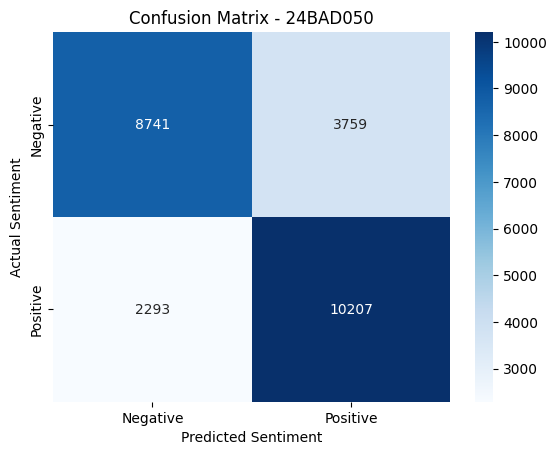

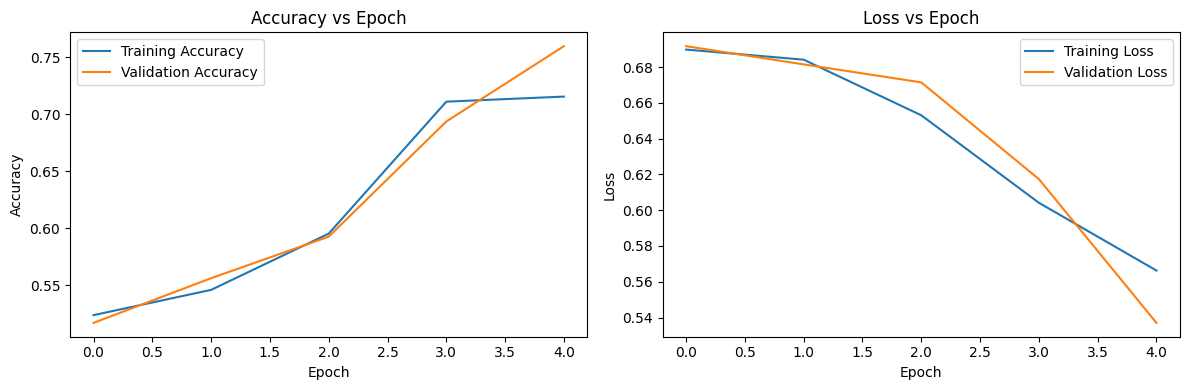

In [4]:
print("24BAD044-Jayaraksha")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_val, y_val)
)
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Training Accuracy:", round(history.history["accuracy"][-1], 4))
print("Validation Accuracy:", round(history.history["val_accuracy"][-1], 4))
print("Training Loss:", round(history.history["loss"][-1], 4))
print("Validation Loss:", round(history.history["val_loss"][-1], 4))
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
y_prob = model.predict(x_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix - 24BAD050")
plt.show()
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
print("24BAD044-Jayaraksha")
def predict_sentiment(review):
    words = review.lower().split()
    sequence = [1]

    for word in words:
        index = word_index.get(word, 2)
        if index >= max_words:
            index = 2
        sequence.append(index + 3 if index != 2 else 2)

    padded = pad_sequences(
        [sequence], maxlen=max_len,
        padding="post", truncating="post"
    )

    probability = model.predict(padded, verbose=0)[0][0]
    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Positive Probability:", round(float(probability), 4))
    return sentiment

reviews = [
    ("This movie was wonderful and the acting was excellent", "Positive"),
    ("The film was boring and a complete waste of time", "Negative"),
    ("I really enjoyed the story and the amazing performances", "Positive"),
    ("The movie was terrible and I hated every minute", "Negative"),
    ("The film was good and entertaining", "Positive"),
    ("The story was dull and the acting was poor", "Negative")
]

for review, expected in reviews:
    predicted = predict_sentiment(review)
    print("Expected Sentiment:", expected)
    print("Correct Prediction:", predicted == expected)
    print("-" * 40)

24BAD044-Jayaraksha
Review: This movie was wonderful and the acting was excellent
Predicted Sentiment: Positive
Positive Probability: 0.7514
Expected Sentiment: Positive
Correct Prediction: True
----------------------------------------
Review: The film was boring and a complete waste of time
Predicted Sentiment: Negative
Positive Probability: 0.1302
Expected Sentiment: Negative
Correct Prediction: True
----------------------------------------
Review: I really enjoyed the story and the amazing performances
Predicted Sentiment: Positive
Positive Probability: 0.7514
Expected Sentiment: Positive
Correct Prediction: True
----------------------------------------
Review: The movie was terrible and I hated every minute
Predicted Sentiment: Negative
Positive Probability: 0.1302
Expected Sentiment: Negative
Correct Prediction: True
----------------------------------------
Review: The film was good and entertaining
Predicted Sentiment: Positive
Positive Probability: 0.7514
Expected Sentiment: Pos